In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# Graf Berarah (4 Node) & Perhitungan PageRank

Graf berarah $G = (V, E)$ dibangun dengan $N = 4$ simpul yaitu $V = \{A, B, C, D\}$ dan $E = 6$ sisi berarah:
- $A \rightarrow B$, $A \rightarrow C$
- $B \rightarrow A$
- $C \rightarrow B$, $C \rightarrow D$
- $D \rightarrow A$

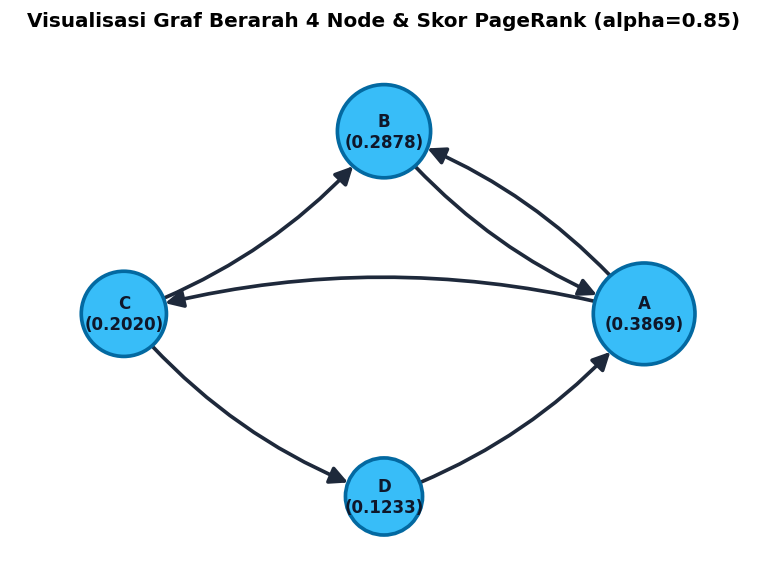

In [2]:
# Inisialisasi graf berarah dengan 4 node
DG = nx.DiGraph()
vertices = ['A', 'B', 'C', 'D']
DG.add_nodes_from(vertices)

# Tambahkan sisi berarah (source -> target)
edges_directed = [
    ('A', 'B'),  # A -> B
    ('A', 'C'),  # A -> C
    ('B', 'A'),  # B -> A
    ('C', 'B'),  # C -> B
    ('C', 'D'),  # C -> D
    ('D', 'A'),  # D -> A
]
DG.add_edges_from(edges_directed)

# Hitung PageRank terlebih dahulu agar ukuran node dapat disesuaikan dengan skor PageRank
pr_85 = nx.pagerank(DG, alpha=0.85, tol=1e-10)

# Visualisasi Graf Berarah 4 Node
plt.figure(figsize=(6.5, 5), dpi=120)
pos = nx.circular_layout(DG)
node_sizes = [1400 + pr_85[n] * 6000 for n in vertices]

nx.draw_networkx_nodes(
    DG, pos,
    nodelist=vertices,
    node_size=node_sizes,
    node_color='#38bdf8',
    edgecolors='#0369a1',
    linewidths=2.2
)
nx.draw_networkx_edges(
    DG, pos,
    width=2.2,
    edge_color='#1e293b',
    arrows=True,
    arrowsize=22,
    arrowstyle='-|>',
    connectionstyle='arc3,rad=0.14',
    node_size=node_sizes
)

labels = {n: f"{n}\n({pr_85[n]:.4f})" for n in vertices}
nx.draw_networkx_labels(DG, pos, labels=labels, font_size=10, font_weight='bold', font_color='#0f172a')

plt.title("Visualisasi Graf Berarah 4 Node & Skor PageRank (alpha=0.85)", fontsize=12, fontweight='bold', pad=16)
plt.margins(0.15)
plt.axis('off')
plt.tight_layout()
plt.show()

---
## 1. Perhitungan PageRank Masing-Masing Node

Rumus PageRank standar (dengan *damping factor* $d = 0.85$):
$$PR(i) = \frac{1 - d}{N} + d \sum_{(j,i) \in E} \frac{PR(j)}{D_{out}(j)}$$

Sedangkan rumus PageRank murni tanpa *damping factor* ($d = 1.0$, sesuai slide materi):
$$P_{PR}(i) = \sum_{(j,i) \in E} \frac{P_{PR}(j)}{D_{out}(j)}$$

In [3]:
# 1. PERHITUNGAN PAGERANK MASING-MASING NODE
pagerank_85 = nx.pagerank(DG, alpha=0.85, tol=1e-10)
pagerank_10 = nx.pagerank(DG, alpha=1.0, max_iter=500, tol=1e-10)

print("1. PAGERANK MASING-MASING NODE (alpha = 0.85):")
for node in vertices:
    print(f"   Node {node} : {pagerank_85[node]:.6f} ({pagerank_85[node] * 100:.2f}%)")
print(f"   Total PageRank = {sum(pagerank_85.values()):.6f}\n")

# Susun tabel ringkasan lengkap
in_deg = dict(DG.in_degree())
out_deg = dict(DG.out_degree())
in_neighbors = {n: ', '.join(sorted(DG.predecessors(n))) for n in vertices}

df_pr = pd.DataFrame({
    'Node': vertices,
    'In-Degree': [in_deg[n] for n in vertices],
    'Out-Degree': [out_deg[n] for n in vertices],
    'Tautan Masuk (Dari)': [in_neighbors[n] for n in vertices],
    'PageRank (alpha=0.85)': [round(pagerank_85[n], 6) for n in vertices],
    'Persentase (%)': [round(pagerank_85[n] * 100, 2) for n in vertices],
    'PageRank Murni (alpha=1.0)': [round(pagerank_10[n], 6) for n in vertices],
})
df_pr_sorted = df_pr.sort_values(by='PageRank (alpha=0.85)', ascending=False).reset_index(drop=True)
df_pr_sorted.index = df_pr_sorted.index + 1
df_pr_sorted.index.name = 'Rank'

print("   Tabel Ringkasan PageRank (Diurutkan dari Rank Tertinggi):")
display(df_pr_sorted)

# Verifikasi dengan Power Iteration manual (d = 0.85)
N = DG.number_of_nodes()
d = 0.85
pr_iter = {n: 1.0 / N for n in vertices}
print("\n   Verifikasi Iterasi Manual Power Iteration (d = 0.85):")
print(f"Iterasi 0 (Inisialisasi 1/N = {1/N:.2f}): " + ", ".join([f"{n}={pr_iter[n]:.4f}" for n in vertices]))
for it in range(1, 21):
    pr_next = {}
    for i in vertices:
        rank_sum = sum(pr_iter[j] / out_deg[j] for j in DG.predecessors(i))
        pr_next[i] = (1 - d) / N + d * rank_sum
    diff = sum(abs(pr_next[n] - pr_iter[n]) for n in vertices)
    pr_iter = pr_next
    if it <= 5 or it in (10, 15, 20):
        print(f"Iterasi {it:2d}: " + ", ".join([f"{n}={pr_iter[n]:.6f}" for n in vertices]) + f"  (delta={diff:.6f})")


1. PAGERANK MASING-MASING NODE (alpha = 0.85):
   Node A : 0.386942 (38.69%)
   Node B : 0.287779 (28.78%)
   Node C : 0.201950 (20.20%)
   Node D : 0.123329 (12.33%)
   Total PageRank = 1.000000

   Tabel Ringkasan PageRank (Diurutkan dari Rank Tertinggi):


,Node,In-Degree,Out-Degree,Tautan Masuk (Dari),PageRank (alpha=0.85),Persentase (%),PageRank Murni (alpha=1.0)
Rank,,,,,,,
1,A,2,2,"B, D",0.386942,38.69,0.4
2,B,2,1,"A, C",0.287779,28.78,0.3
3,C,1,2,A,0.201950,20.20,0.2
4,D,1,1,C,0.123329,12.33,0.1



   Verifikasi Iterasi Manual Power Iteration (d = 0.85):
Iterasi 0 (Inisialisasi 1/N = 0.25): A=0.2500, B=0.2500, C=0.2500, D=0.2500
Iterasi  1: A=0.462500, B=0.250000, C=0.143750, D=0.143750  (delta=0.425000)
Iterasi  2: A=0.372188, B=0.295156, C=0.234063, D=0.098594  (delta=0.270938)
Iterasi  3: A=0.372188, B=0.295156, C=0.195680, D=0.136977  (delta=0.076766)
Iterasi  4: A=0.404813, B=0.278844, C=0.195680, D=0.120664  (delta=0.065251)
Iterasi  5: A=0.377081, B=0.292709, C=0.209545, D=0.120664  (delta=0.055463)
Iterasi 10: A=0.386691, B=0.287905, C=0.202497, D=0.122908  (delta=0.004614)
Iterasi 15: A=0.386975, B=0.287763, C=0.201964, D=0.123299  (delta=0.000171)
Iterasi 20: A=0.386947, B=0.287777, C=0.201948, D=0.123328  (delta=0.000019)
